# Lecture 8 — Class Exercise
## Choropleth Maps

> **Push to:** `week08/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


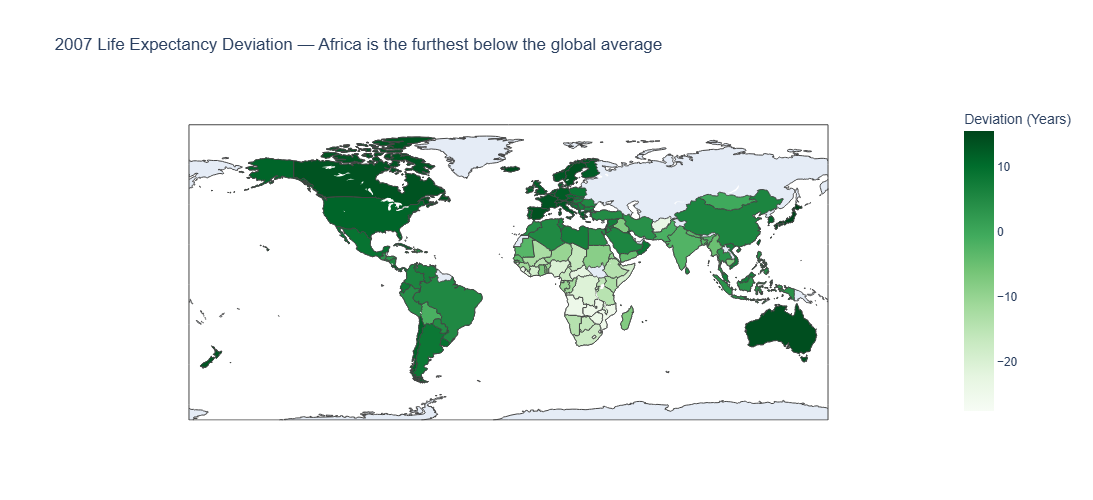

In [4]:
# Task 1
# YOUR CODE HERE
df = px.data.gapminder()
gm_2007 = df[df['year'] == 2007].copy()

global_mean = gm_2007['lifeExp'].mean()

gm_2007['lifeExp_deviation'] = gm_2007['lifeExp'] - global_mean

continent_dev = gm_2007.groupby('continent')['lifeExp_deviation'].mean()
worst_continent = continent_dev.idxmin()

fig = px.choropleth(
    gm_2007,
    locationmode='ISO-3',
    locations='iso_alpha',
    color='lifeExp_deviation',
    color_continuous_scale='Greens',
    hover_name='country',
    hover_data={
        'lifeExp': ':.1f',
        'lifeExp_deviation': ':.2f'
    },
    labels={'lifeExp_deviation': 'Deviation (Years)', 'lifeExp': 'Life Expectancy'},
    title=f'2007 Life Expectancy Deviation — {worst_continent} is the furthest below the global average',
    height=500,
    width=900
)
fig.update_layout(
    font=dict(family='Arial', size=12),
)
fig.show()


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *https://github.com/longwosion/geojson-map-china/blob/master/geometryProvince/35.json*

**Chart type chosen** `px.choropleth_mapbox` **and reason:**

*I chose `px.choropleth_mapbox` over a standard `px.choropleth` because it allows me to overlay the population data onto an interactive, styled basemap (e.g., 'carto-positron'). This provides better geographical context and allows users to zoom and pan across the province, making the visualization more engaging.*

**Colour scale chosen** (sequential or diverging) **and reason:**

*I chose a **sequential** colour scale (specifically 'Oranges'). Population data is a continuous, non-negative metric where higher values simply represent a larger magnitude. There is no meaningful central point (like zero or an average) to diverge from, so a sequential scale effectively communicates the gradual increase in population density across different cities.*


{'id': '3507', 'name': '南平市', 'cp': [118.136, 27.2845], 'childNum': 10}


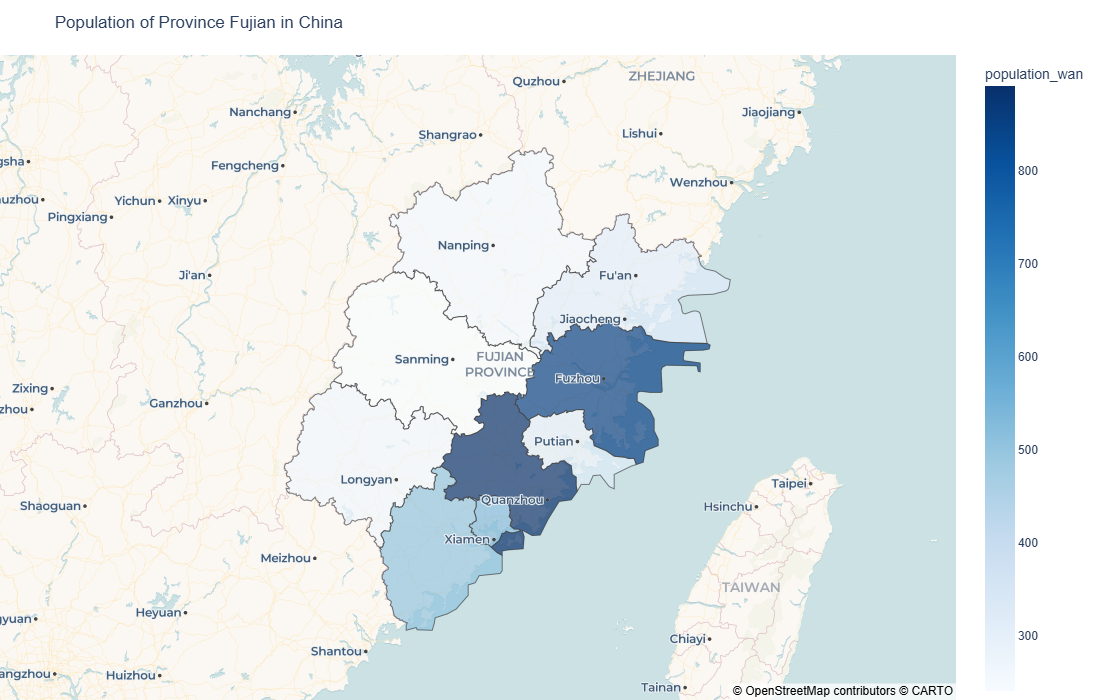

In [5]:
# Task 2
# YOUR CODE HERE

# Load your GeoJSON
# with open('your_file.geojson', 'r') as file:
#     my_geojson = json.load(file)

with open('35.json', 'r', encoding='utf-8') as file:
    my_geojson = json.load(file)

# Inspect the properties to find the right featureidkey
# print(my_geojson['features'][0]['properties'])

print(my_geojson['features'][0]['properties'])

data = {
    'city': ['泉州市', '福州市', '厦门市', '漳州市', '莆田市', '宁德市', '龙岩市', '南平市', '三明市'],
    'population_wan': [891.4, 850.1, 535.0, 507.6, 319.2, 
                       316.7, 268.8, 262.3, 241.9]
}

df_fujian_pop = pd.DataFrame(data)

fig = px.choropleth_map(
    data_frame=df_fujian_pop,
    geojson=my_geojson,
    locations='city',
    featureidkey='properties.name',
    color='population_wan',
    color_continuous_scale='Blues',
    hover_name='city',
    hover_data={'city': False},
    labels={'Population': 'Population (2024)'},
    title='Population of Province Fujian in China',
    center={'lat': 26.07, 'lon': 117.98},
    zoom=6,
    opacity=0.7,
    height=700
)
fig.update_layout(
    font=dict(family='Arial', size=12),
    margin=dict(l=0, r=0, t=55, b=0),
)
fig.show()